# 04. Bridge to Optimization: From Price Forecasts to a Procurement Plan

**Block 4 of the project.** A forecast is only useful if a decision changes because of it. This notebook states the optimization problem our price forecasts feed, solves a small illustrative version with the backtest forecasts from Notebook 03, and lists what currently limits a real one.

**Everything in Sections 2–4 that is not a published price is an assumption**, chosen to be plausible and labelled as such. The point is the structure and the link between forecast quality and decision quality, not the specific UAH amounts.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.optimize import linprog

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "results").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the project root containing results/")
sys.path.insert(0, str(ROOT / "src"))
from reporting import style
style.apply()

backtest = pd.read_csv(ROOT / "results" / "backtest_results.csv", parse_dates=["origin", "date"])
backtest["product"] = backtest["good"].map(style.LABELS)

## 1. The Decision Problem

**Who decides what.** A buyer with a fixed monthly need, for example a network of school or hospital canteens, has to supply $D$ kg of carrots every month for the next 12 months. Each month it can buy at that month's price, or buy more when prices are low and store the surplus. Storage costs money and part of the stock spoils.

Carrot and potato prices swing 60–95% within a year (Notebook 02), so *when* to buy matters. That is exactly what a 12-month price forecast informs.

**Linear program**, months $t = 1,\dots,12$:

$$
\min_{q,\,I}\; \sum_{t=1}^{12} \big(\hat p_t\, q_t + h\, I_t\big)
$$

subject to

$$
I_t = (1-\delta)\, I_{t-1} + q_t - D \quad (\text{stock balance}), \qquad I_0 = 0,
$$
$$
0 \le I_t \le C \quad (\text{demand always met, storage capacity}), \qquad q_t \ge 0 .
$$

| Symbol | Meaning | Source |
|---|---|---|
| $q_t$ | kg bought in month $t$ | **decision** |
| $I_t$ | kg in storage at the end of month $t$ | **decision** (state) |
| $\hat p_t$ | price per kg in month $t$ | **forecast from Block 3** (ETS, SARIMA, ...) |
| $D$ | monthly need, kg | assumption |
| $\delta$ | share of stock lost per month | assumption |
| $h$ | storage cost, UAH per kg per month | assumption |
| $C$ | storage capacity, kg | assumption |

The plan is made once, at the forecast origin, using forecast prices. It is then **executed and scored at the actual published prices**, which is how a forecast error becomes a money error.

In [2]:
# Illustrative assumptions (not from the data)
DEMAND = 1_000        # kg per month
SPOILAGE = 0.03       # 3% of stored stock lost per month (cold-stored root vegetables)
HOLDING = 0.5         # UAH per kg per month
CAPACITY = 4_000      # kg, about four months of demand
MONTHS = 12


def plan_purchases(prices, spoilage=SPOILAGE):
    # Solve the LP above for one 12-month price path; returns (purchases, end-of-month stock).
    T = len(prices)
    cost = np.r_[prices, np.full(T, HOLDING)]            # variables: q_1..q_T, I_1..I_T
    balance = np.zeros((T, 2 * T))
    for t in range(T):
        balance[t, t] = 1.0                               # + q_t
        balance[t, T + t] = -1.0                          # - I_t
        if t > 0:
            balance[t, T + t - 1] = 1.0 - spoilage        # + (1 - delta) I_{t-1}
    result = linprog(cost, A_eq=balance, b_eq=np.full(T, DEMAND),
                     bounds=[(0, None)] * T + [(0, CAPACITY)] * T, method="highs")
    if result.status != 0:
        raise RuntimeError(f"LP not solved: {result.message}")
    return result.x[:T], result.x[T:]


def executed_cost(actual_prices, purchases, stock):
    # What the plan really costs once the published prices are known.
    return float(actual_prices @ purchases + HOLDING * stock.sum())

## 2. One Plan in Detail: Carrots, July 2024 – June 2025

The planner stands at the July 2024 origin, takes the ETS forecast for the next 12 months, and solves the LP.

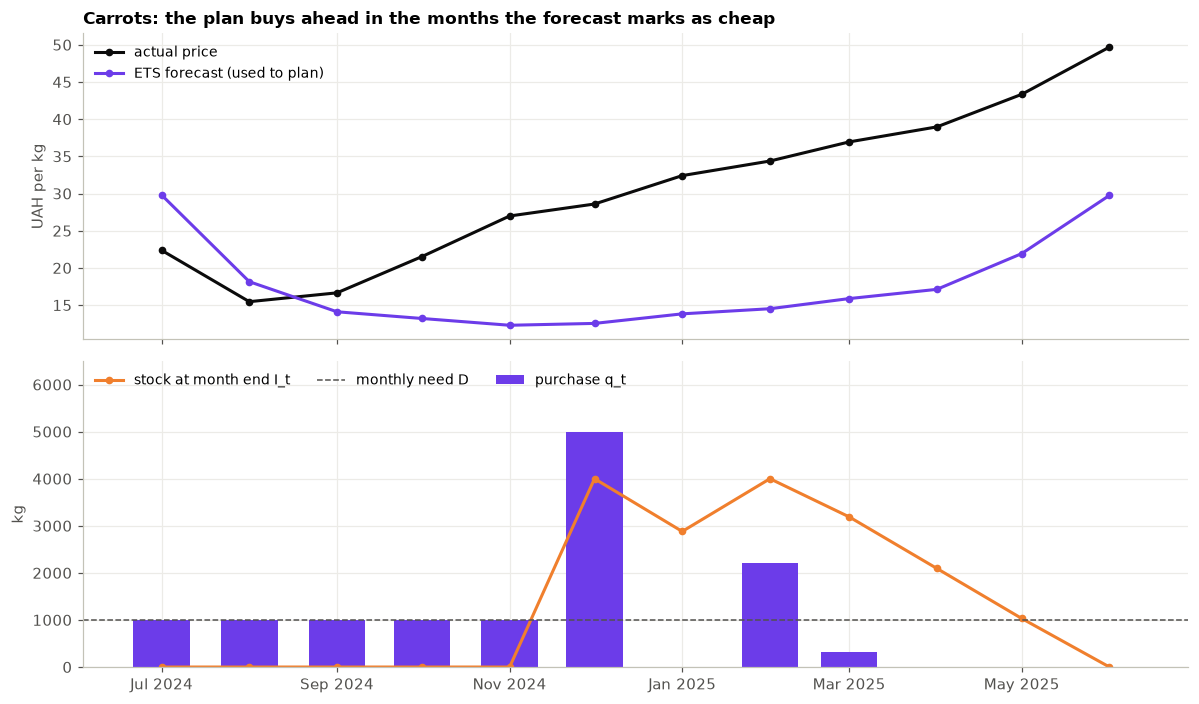

Buy every month:              367,280 UAH
Plan from ETS forecast:       341,791 UAH  (6.9% saved)
Plan with perfect foresight:  308,040 UAH  (16.1% saved)


In [3]:
window = backtest[(backtest["product"] == "Carrot") & (backtest.origin == "2024-07-01")]
actual = window[window.model == "naive"].sort_values("h")
dates, actual_price = pd.DatetimeIndex(actual.date), actual.y.values
ets_price = window[window.model == "ETS"].sort_values("h").yhat.values
purchases, stock = plan_purchases(ets_price)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
top.plot(dates, actual_price, color=style.ACTUAL_COLOR, marker="o", markersize=4, label="actual price")
top.plot(dates, ets_price, color=style.MODEL_COLORS["ETS"], marker="o", markersize=4, label="ETS forecast (used to plan)")
top.set_ylabel("UAH per kg")
top.set_title("Carrots: the plan buys ahead in the months the forecast marks as cheap")
top.legend(fontsize=9)
bottom.bar(dates, purchases, width=20, color=style.MODEL_COLORS["ETS"], label="purchase q_t")
bottom.plot(dates, stock, color=style.MODEL_COLORS["SARIMA"], marker="o", markersize=4, label="stock at month end I_t")
bottom.axhline(DEMAND, color=style.MUTED, linestyle="--", linewidth=1, label="monthly need D")
bottom.set_ylabel("kg")
bottom.set_ylim(0, purchases.max() * 1.3)
bottom.legend(fontsize=9, ncol=3, loc="upper left")
bottom.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()
style.save(fig, "optimization_plan_carrot")
plt.show()

buy_monthly = executed_cost(actual_price, np.full(MONTHS, float(DEMAND)), np.zeros(MONTHS))
with_ets = executed_cost(actual_price, purchases, stock)
hindsight = executed_cost(actual_price, *plan_purchases(actual_price))
print(f"Buy every month:            {buy_monthly:>9,.0f} UAH")
print(f"Plan from ETS forecast:     {with_ets:>9,.0f} UAH  ({100 * (1 - with_ets / buy_monthly):.1f}% saved)")
print(f"Plan with perfect foresight:{hindsight:>9,.0f} UAH  ({100 * (1 - hindsight / buy_monthly):.1f}% saved)")

## 3. Does a Better Forecast Give a Better Plan? All Ten Origins

For each backtest origin and each forecasting model, plan with that model's forecast and score the plan at actual prices. Two reference points:

- **Buy every month**: no planning, cost = $\sum_t p_t D$. Savings are measured against this.
- **Perfect foresight**: plan with the actual prices. The best any forecast could achieve under these assumptions.

A flat forecast (naive) gives no reason to store anything, so it always reproduces "buy every month".

In [4]:
PLAN_MODELS = ["naive", "seasonal_naive", "ETS", "SARIMA"]
rows = []
for product in ["Carrot", "Potato"]:
    for origin, window in backtest[backtest["product"] == product].groupby("origin"):
        actual_price = window[window.model == "naive"].sort_values("h").y.values
        baseline = executed_cost(actual_price, np.full(MONTHS, float(DEMAND)), np.zeros(MONTHS))
        row = {"product": product, "origin": origin,
               "perfect foresight": 1 - executed_cost(actual_price, *plan_purchases(actual_price)) / baseline}
        for model in PLAN_MODELS:
            forecast = window[window.model == model].sort_values("h").yhat.values
            row[model] = 1 - executed_cost(actual_price, *plan_purchases(forecast)) / baseline
        rows.append(row)
savings = pd.DataFrame(rows)
columns = PLAN_MODELS + ["perfect foresight"]
summary = savings.groupby("product")[columns].mean().loc[["Carrot", "Potato"]]
summary["ETS share of possible saving"] = summary["ETS"] / summary["perfect foresight"]
print("Mean saving vs buying every month, 10 origins (negative = the plan cost more):")
display(summary.style.format("{:.1%}"))
print("Origins where the ETS plan cost more than buying every month:")
display(savings.groupby("product")["ETS"].apply(lambda s: f"{(s < 0).sum()} of {len(s)}").to_frame("ETS plan worse"))

Mean saving vs buying every month, 10 origins (negative = the plan cost more):


,naive,seasonal_naive,ETS,SARIMA,perfect foresight,ETS share of possible saving
product,,,,,,
Carrot,0.0%,7.6%,7.5%,8.1%,15.3%,49.1%
Potato,0.0%,-1.3%,-1.1%,-1.1%,5.5%,-19.5%


Origins where the ETS plan cost more than buying every month:


,ETS plan worse
product,
Carrot,0 of 10
Potato,7 of 10


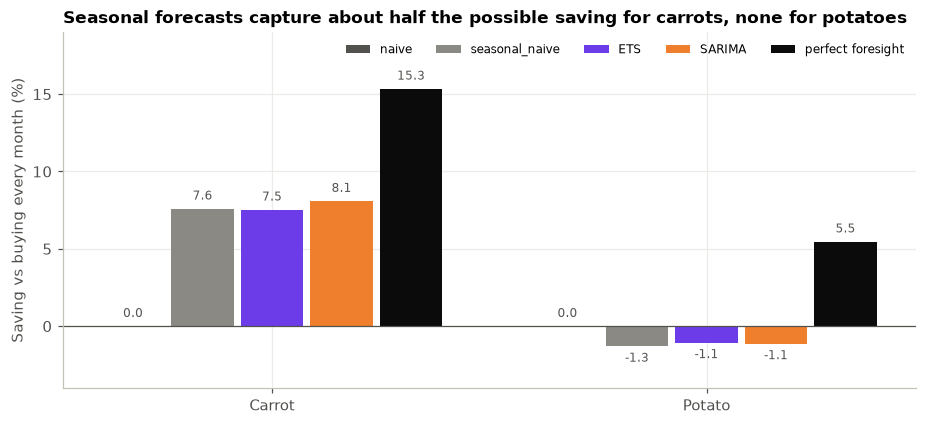

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bar_colors = {**{m: style.MODEL_COLORS[m] for m in PLAN_MODELS}, "perfect foresight": style.ACTUAL_COLOR}
width = 0.16
x = np.arange(len(summary.index))
for i, column in enumerate(columns):
    values = 100 * summary[column].values
    bars = ax.bar(x + (i - 2) * width, values, width=width * 0.9, color=bar_colors[column], label=column)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + (0.4 if value >= 0 else -0.4), f"{value:.1f}",
                ha="center", va="bottom" if value >= 0 else "top", fontsize=8, color=style.MUTED)
ax.axhline(0, color=style.MUTED, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_ylabel("Saving vs buying every month (%)")
ax.set_title("Seasonal forecasts capture about half the possible saving for carrots, none for potatoes")
ax.legend(fontsize=8, ncol=5, loc="upper right")
ax.set_ylim(-4, 19)
style.save(fig, "optimization_savings")
plt.show()

**Reading the result.** Carrots have a stable seasonal cycle (seasonal strength 0.64 in Notebook 02); ETS and SARIMA predict the autumn trough well enough to recover roughly half of the perfect-foresight saving. Potatoes have a weak, shifting cycle (0.26), so a plan that stores ahead for a forecast dip pays storage and spoilage for savings that often do not arrive: it cost more than buying every month in 7 of 10 origins.

Seasonal naive, the *worst* model by MASE in Notebook 03, plans carrots as well as ETS (7.6% vs 7.5%): the plan needs only the **timing** of the cheap months, which last year's pattern gives, not the price level, which it gets badly wrong. The same forecast accuracy number (MASE) can therefore be worth a lot or nothing, depending on whether the error falls on the timing of the price trough. That is why the next stage should judge models by **decision cost** as well as MASE.

In [6]:
# How much does the carrot conclusion depend on the assumed spoilage rate?
sensitivity = []
for spoilage in [0.01, 0.03, 0.06]:
    for origin, window in backtest[backtest["product"] == "Carrot"].groupby("origin"):
        actual_price = window[window.model == "naive"].sort_values("h").y.values
        baseline = executed_cost(actual_price, np.full(MONTHS, float(DEMAND)), np.zeros(MONTHS))
        ets = window[window.model == "ETS"].sort_values("h").yhat.values
        sensitivity.append({"monthly spoilage": f"{spoilage:.0%}",
            "ETS plan": 1 - executed_cost(actual_price, *plan_purchases(ets, spoilage)) / baseline,
            "perfect foresight": 1 - executed_cost(actual_price, *plan_purchases(actual_price, spoilage)) / baseline})
display(pd.DataFrame(sensitivity).groupby("monthly spoilage", sort=False).mean().style.format("{:.1%}"))

,ETS plan,perfect foresight
monthly spoilage,,
1%,10.3%,18.1%
3%,7.5%,15.3%
6%,4.7%,11.7%


## 4. Current Limitations

**Data**
- The source publishes **retail average prices**. A bulk buyer pays wholesale or contract prices, which follow the retail cycle but at a different level and with a lag.
- There are **no quantities**: no sales, demand, or stock data. Demand is therefore fixed by assumption, and price elasticity or any selling-side decision (pricing, revenue) cannot be estimated from this dataset.
- National averages hide regional differences; regional series have more gaps after 2022 (Notebook 01).

**Forecasts**
- Point forecasts only. The LP treats them as certain, so a confidently wrong trough leads to over-buying (the potato case).
- The 2022 regime break and short history (102 months, 10 backtest origins) make every comparison noisy; SARIMA failed to converge in 12 of 60 fits.

**Optimization**
- Parameters $D, \delta, h, C$ are assumptions; the spoilage sensitivity above shows the conclusion holds but the saving size depends on them.
- One product at a time, linear costs, no minimum order size, budget, or fixed delivery cost.
- The plan is fixed at the origin; a real buyer would re-plan monthly as new prices arrive.

## 5. Next Steps

1. **Forecast uncertainty into the decision:** prediction intervals or simulated price paths, then scenario-based (stochastic) or robust optimization instead of a single forecast.
2. **Rolling re-planning:** re-solve every month with the updated forecast and execute only the first month (model-predictive control).
3. **Evaluate models by decision cost**, not only MASE, since the two can disagree.
4. **Richer forecasts:** ML and regression models with exogenous drivers (exchange rate, fuel price, harvest data), always benchmarked against naive.
5. **Realistic inputs:** wholesale prices, real storage costs and spoilage rates, multi-product plans with a shared budget and warehouse.